<a href="https://colab.research.google.com/github/jfbadarom/Fisica-com-Python/blob/main/Tarefa_3_Jo%C3%A3o_Felipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 1 - Gás de Ehrenfest

In [1]:
import numpy as np
import random as rd
import matplotlib.pyplot as plt
from statistics import variance, mean


Vamos aplicar o modelo de Ehrenfest e verificar então sua média e sua variância, bem como sua distribuição de equilibrio e a sua forma assintótica no limite de N>>1.

Text(0.5, 1.0, 'Evolução temporal do número de partículas no compartimento A')

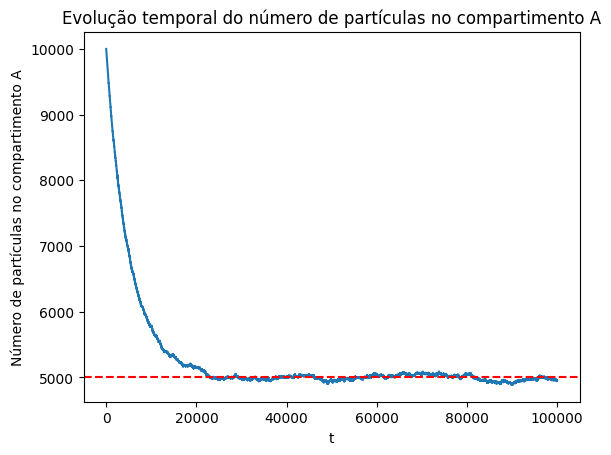

In [ ]:
N=10000 #Número total de partículas
Na=N #Número de partículas no compartimento A
NaList=[]
tvec=np.arange(0,10*N,1)
for t in tvec:
  rand=rd.random()#Sorteio
  if rand<(Na/N): #Se o número sorteado for menor que a probabilidade de troca de uma partícula de A para B então o compartimento A perde um partícula
    Na=Na-1
  else: #Se for menor o compartimento A ganha uma partícula
    Na=Na+1
  NaList.append(Na)

plt.plot(tvec,NaList)
plt.xlabel('t')
plt.ylabel('Número de partículas no compartimento A')
plt.axhline(y=N/2, color='r', linestyle='--')
plt.title('Evolução temporal do número de partículas no compartimento A')



In [ ]:
def Ehrenfest_it(N,N_a,t):
  NaList=[]
  Na=N_a
  tvec=np.arange(0,t,1)
  for t in tvec:
    rand=rd.random()#Sorteio
    if rand<(Na/N): #Se o número sorteado for menor que a probabilidade de troca de uma partícula de A para B então o compartimento A perde um partícula
      Na=Na-1
    else: #Se for menor o compartimento A ganha uma partícula
      Na=Na+1
    NaList.append(Na)
  return NaList, tvec

Aqui já é possível perceber que o número de partículas depois de um certo tempo de iteração oscila em torno de N/2. Vamos então calcular a média dessa distribuição e a variância. E comparar com a função que obtemos para a média e a variância

### Média e Variância

In [ ]:
def f_med(N,t):
  return N/2 + (1-2/N)**t*(N/2) #Média teórica
def f_var(N,t):
  return N/4 + (1-4/N)**t*((N/2)**2-N/4)-(1-2/N)**(2*t)*(N/2)**2#Variância teórica

In [ ]:
N=1000
Na_t, tvec =Ehrenfest_it(N, N, 4*N)
NaMatrix=[]
for j in tvec:
  Na_t, tvec =Ehrenfest_it(N, N, 4*N)
  NaMatrix.append(Na_t)#Conjunto de simulações



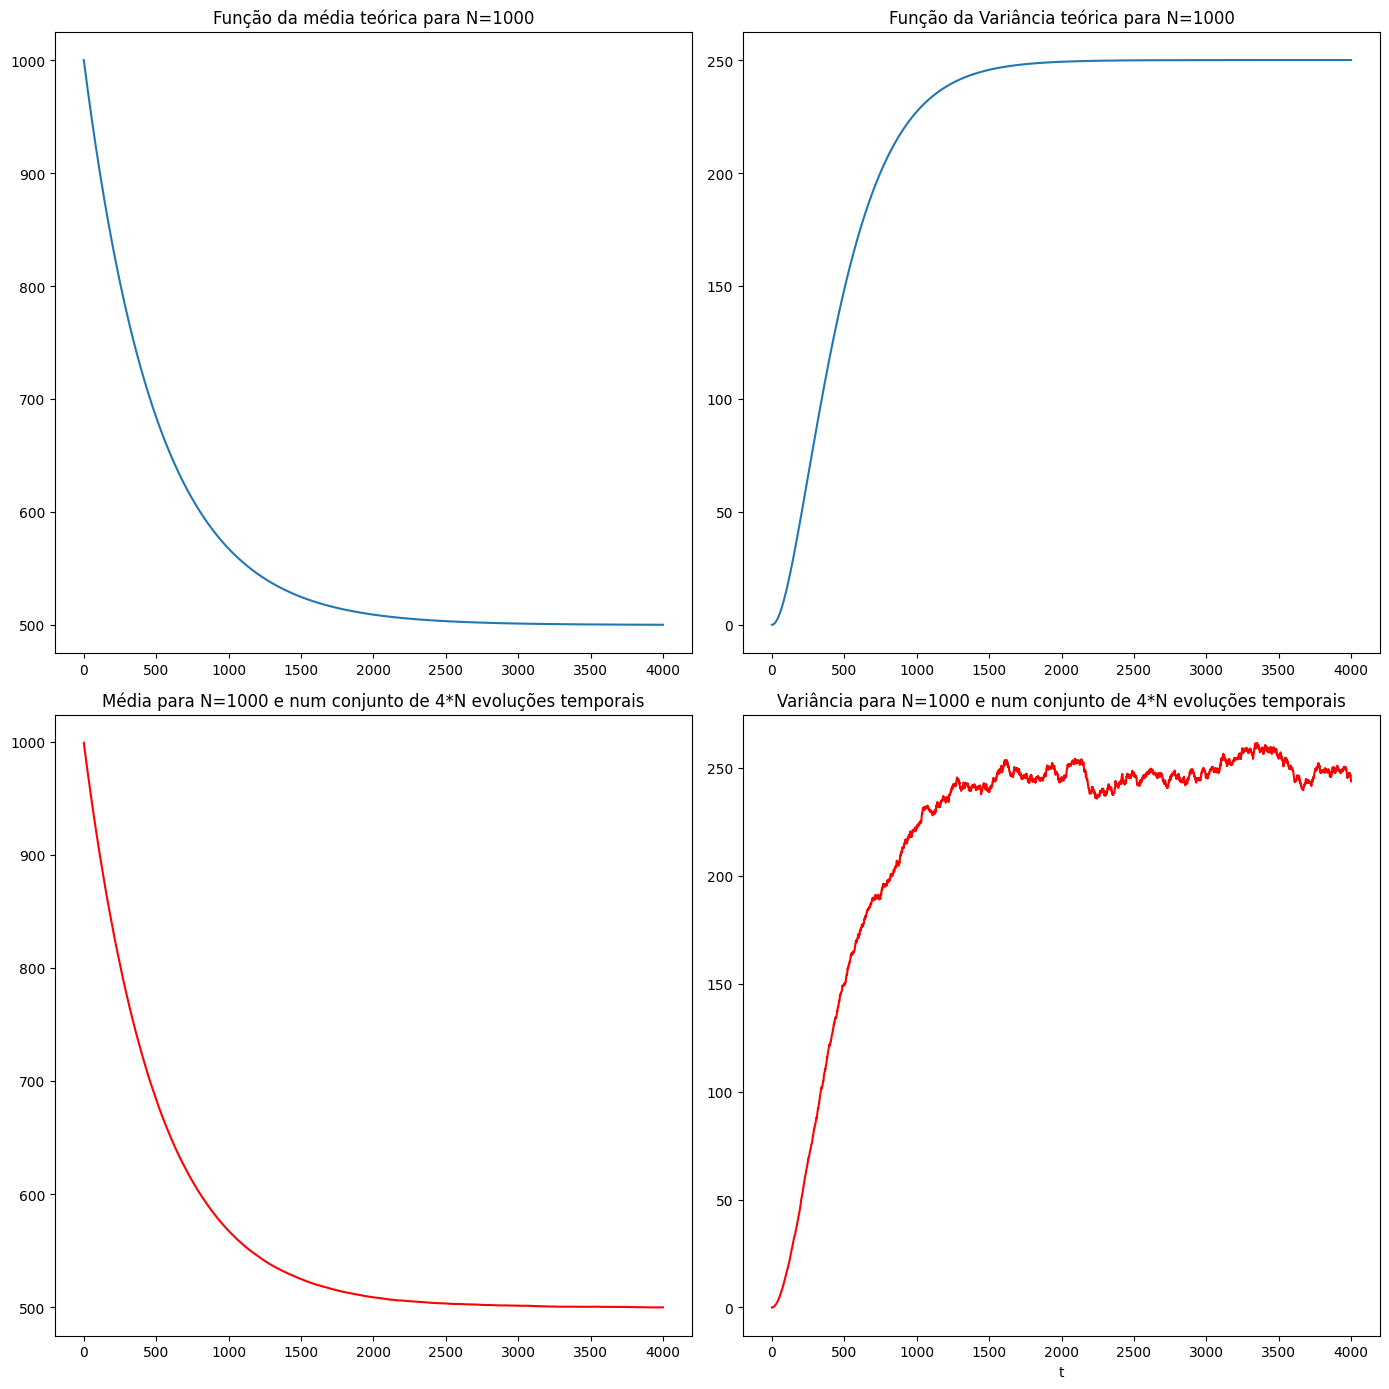

In [ ]:
media_n_t=[]
var_n_t=[]
fig, ax=plt.subplots(2,2, figsize=(14,14))
for i in range(4*N): #Iterando no tempo
  Na_t_list=[]
  for j in range(4*N): #Iterando no essemble
    Na_t_list.append(NaMatrix[j][i])
  media_n_t.append(mean(Na_t_list))
  var_n_t.append(variance(Na_t_list))
ax[1,0].plot(tvec,media_n_t, color='r')
ax[1,0].set_title("Média para N=1000 e num conjunto de 4*N evoluções temporais")
ax[0,0].plot(tvec,f_med(N,tvec))
ax[0,0].set_title("Função da média teórica para N=1000")
plt.tight_layout()
ax[1,1].plot(tvec,var_n_t, color='r')
ax[1,1].set_title("Variância para N=1000 e num conjunto de 4*N evoluções temporais")
ax[0,1].plot(tvec,f_var(N,tvec))
ax[0,1].set_title("Função da Variância teórica para N=1000")
plt.xlabel('t')
plt.tight_layout()

Média de partículas cai para N/2 e a variância vai para N/4 no equilibrio, concordando com os resultados teóricos.

### Distribuição de equilíbrio

Vamos agora comparar a distribuição desse conjunto de 1000 evoluções com a distribuição teórica. Como a distribuição é no equilibrio vamos escolher um tempo no qual a distribuição o sistema já entrou no equilíbrio t=3000.

In [ ]:
import scipy.special as scipy

In [ ]:
def eq_dist(n,N):
  return (1/2)**N*scipy.comb(N,n)

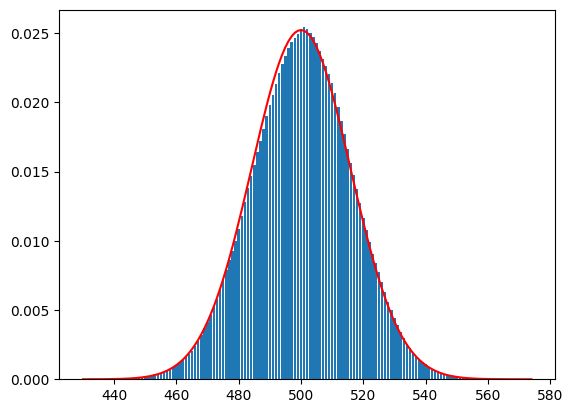

In [ ]:
vetor = [item for sublista in NaMatrix for item in sublista[3000:]]
val, ocur = np.unique(vetor, return_counts=True)
plt.bar(val, ocur/sum(ocur))
plt.plot(val, eq_dist(val,N),color='red')



Perceba que o corte em t=3000, embora a distribuição teórica faça uma envoltória bem próxima da distribuição do sistema, ainda há um leve desvio da distribuição para a direita, o que indica que para melhorar ainda mais esse fit uma alternativa seria aumentar o tempo de iteração e pegar um corte com um valor de t mais alto.

Para N>>1

In [ ]:
def eq_dist_2(n,N):
  return np.sqrt(2*(N*np.pi))*np.exp(-2*(n-N/2)**2/N)

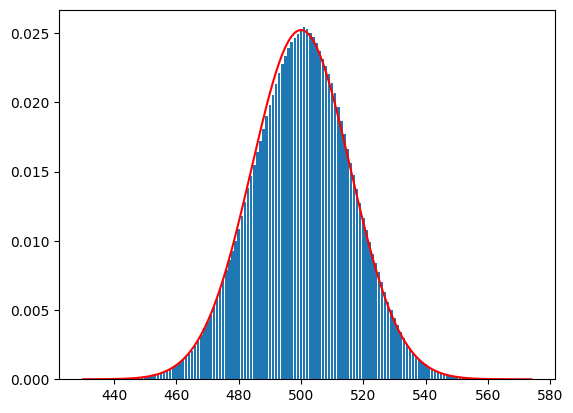

In [ ]:
plt.bar(val, ocur/sum(ocur))
plt.plot(val, eq_dist_2(val,N)/sum(eq_dist_2(val,N)),color='red')

Perceba que para N=1000, a distribuição gaussiana já se aproxima bem dos dados, mas como o corte ainda foi feito em t=3000 ainda hhá um leve deslocamento da distribuição simulada para a direita.

# Parte 2 - Modelo de trocas cinéticas e distribuição de Boltzmann

In [ ]:
N=10**3
E=2*np.random.rand(N)#Vetor de energias
print(np.shape(E))
tvec=[0,10,100,1000,10000,100000]

(1000,)


In [ ]:
t=0
E_t=[]
while t<=tvec[-1]:
    i=rd.randint(0, N-1) #Escolhe a partícula i
    j=rd.randint(0, N-1) #Escolhe a partícula j

    eps=rd.random()#Enegia trocada
    for k in tvec:
        if t==k:
          E_t.append(E.copy())
    if i!=j:
      delta=((1-eps)*E[i]-eps*E[j])
      if delta<= E[i]:
        E[i]=E[i]-delta
        E[j]=E[j]+delta

      t=t+1#Se i=j realiza o sorteio novamente e o tempo não segue, se for diferente o tempo segue


0
10
100
1000
10000
100000


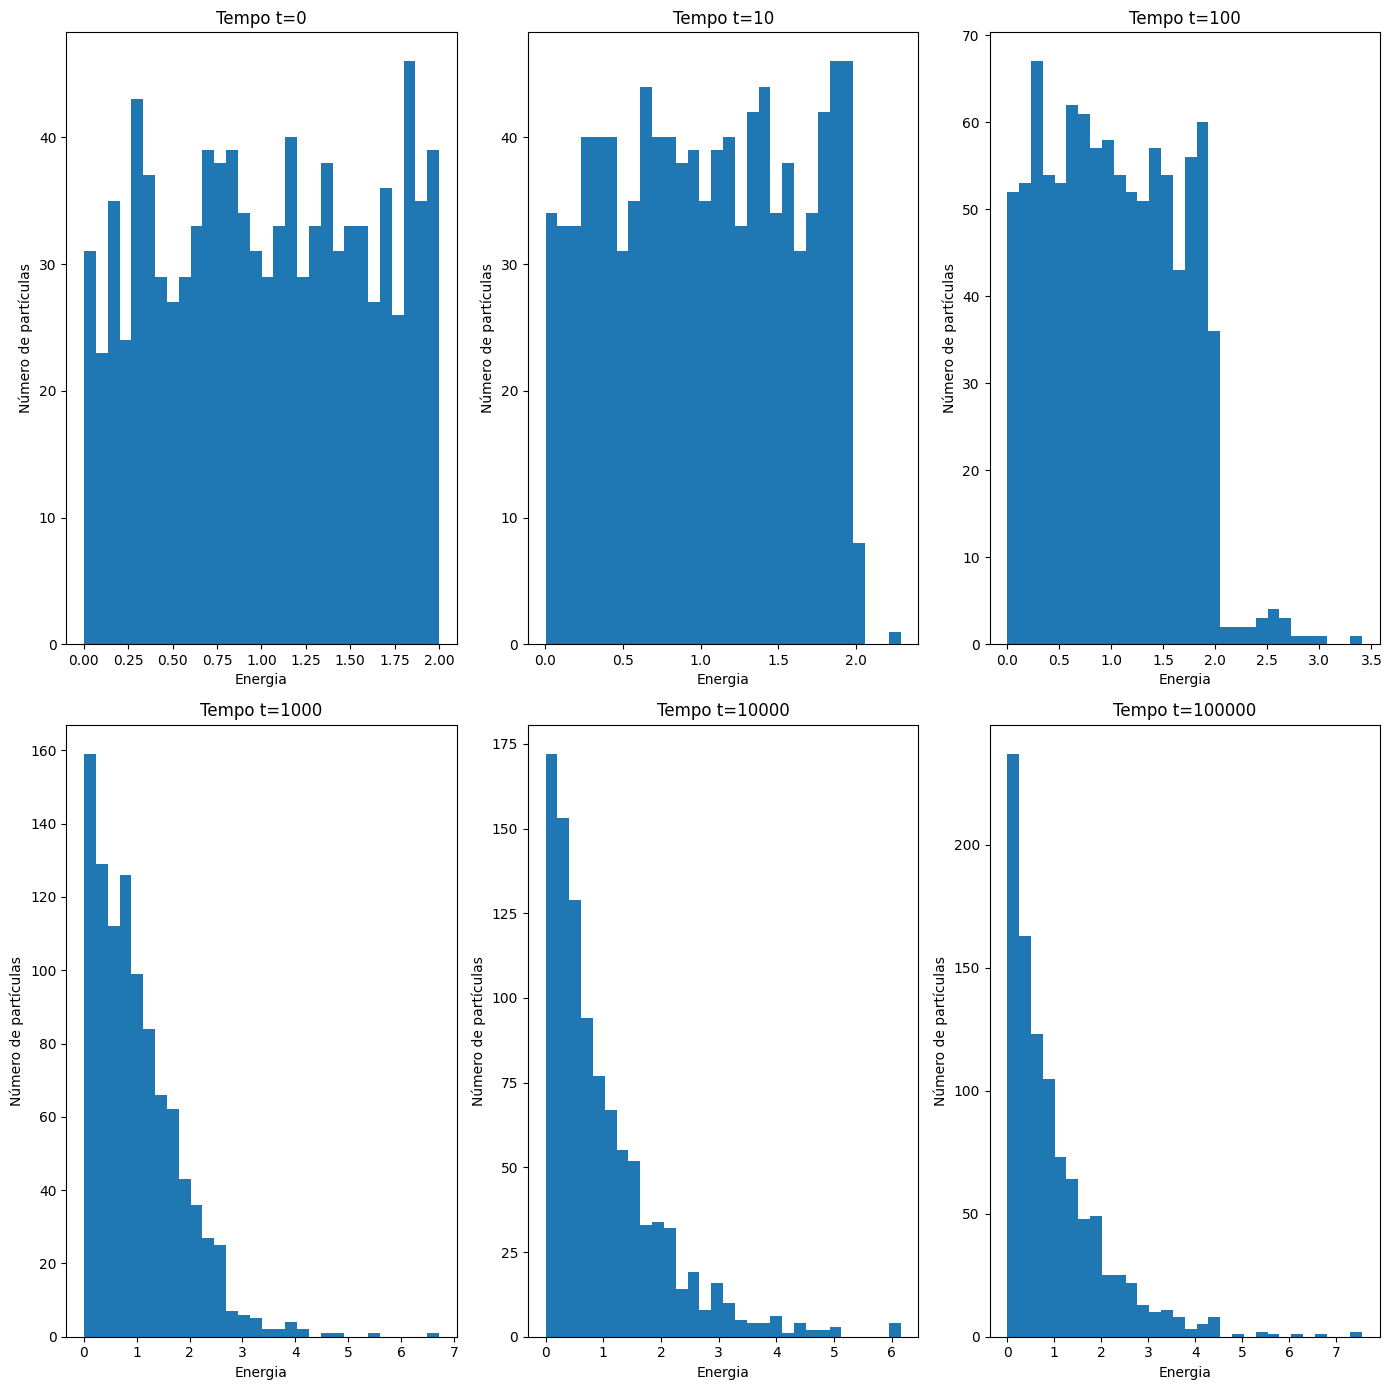

In [ ]:
from numpy._core.defchararray import mod
from math import log10

fig, ax=plt.subplots(2,3, figsize=(14,14))
for t in tvec:
  if np.log10(t+1)<=3:
    ax[0,int(np.mod(np.log10(t+1),3))].hist(E_t[int(np.log10(t+1))],bins=30)
    ax[0,int(np.mod(np.log10(t+1),3))].set_title(f"Tempo t={t}")
    ax[0,int(np.mod(np.log10(t+1),3))].set_xlabel("Energia")
    ax[0,int(np.mod(np.log10(t+1),3))].set_ylabel("Número de partículas")
  else:
    ax[1,int(np.mod(np.log10(t+1),3))].hist(E_t[int(np.log10(t+1))],bins=30)
    ax[1,int(np.mod(np.log10(t+1),3))].set_title(f"Tempo t={t}")
    ax[1,int(np.mod(np.log10(t+1),3))].set_xlabel("Energia")
    ax[1,int(np.mod(np.log10(t+1),3))].set_ylabel("Número de partículas")
plt.tight_layout()



PAra calcular a média e o parametro β agora é bem simples

In [ ]:
print(f"Média = {mean(E_t[-1])}")
print(f"Beta = {1/mean(E_t[-1])}")


Média = 1.022984346185612
Beta = 0.9775320646192549


Por fim vamos comparar com a distribuição de Boltzmann-Gibbs em cada tempo com o valor de β simulado


In [ ]:
def bg(beta, e):
  return beta*np.exp(-beta*e)

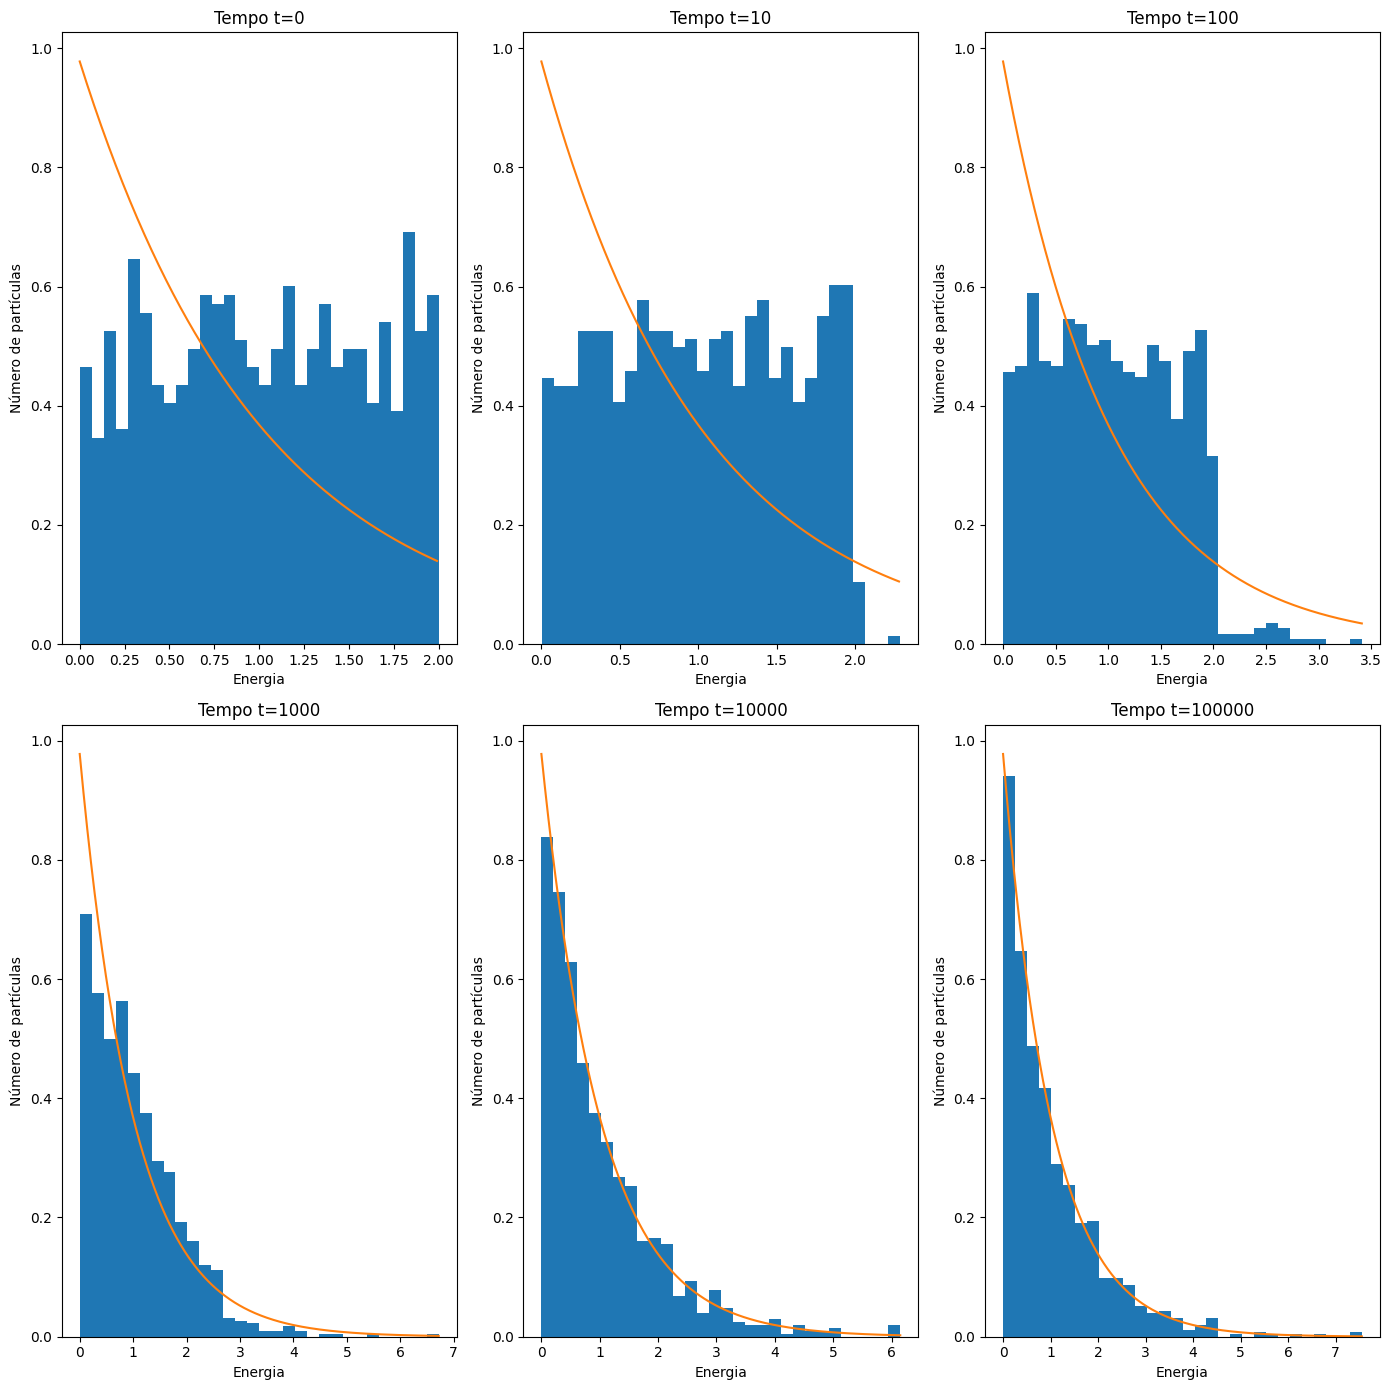

In [ ]:
from numpy._core.defchararray import mod
from math import log10

fig, ax=plt.subplots(2,3, figsize=(14,14))
for t in tvec:
  if np.log10(t+1)<=3:
    ax[0,int(np.mod(np.log10(t+1),3))].hist(E_t[int(np.log10(t+1))],bins=30,density=True)
    ax[0,int(np.mod(np.log10(t+1),3))].set_title(f"Tempo t={t}")
    ax[0,int(np.mod(np.log10(t+1),3))].set_xlabel("Energia")
    ax[0,int(np.mod(np.log10(t+1),3))].set_ylabel("Número de partículas")
    envec=np.arange(0,max(E_t[int(np.log10(t+1))]),0.01)
    ax[0,int(np.mod(np.log10(t+1),3))].plot(envec,bg(1/mean(E_t[int(np.log10(t+1))]),envec))
  else:
    ax[1,int(np.mod(np.log10(t+1),3))].hist(E_t[int(np.log10(t+1))],bins=30, density=True)
    ax[1,int(np.mod(np.log10(t+1),3))].set_title(f"Tempo t={t}")
    ax[1,int(np.mod(np.log10(t+1),3))].set_xlabel("Energia")
    ax[1,int(np.mod(np.log10(t+1),3))].set_ylabel("Número de partículas")
    envec=np.arange(0,max(E_t[int(np.log10(t+1))]),0.01)
    ax[1,int(np.mod(np.log10(t+1),3))].plot(envec,bg(1/mean(E_t[int(np.log10(t+1))]),envec))

plt.tight_layout()


Aqui é possível perceber que conforme o tempo evolui a distribuição de energias tende a distribuição de Boltzmann Gibbs.

Questões

1.   Com a evolução temporal do sistema ele sai de uma distribuição inicial aleatória na qual todos os valores de energia são equiprováveis e se encaminha para uma distribuição onde as partículas tendem a ter uma energia baixa e algumas poucas partículas vão ganhando energia e ficam com suas energias altas

2.   A convergência já pode ser notada a partir de 10^3, mas em 10^5 é distribuição de boltzman faz uma envoltoria muito próxima da distribuição.

3.   A energia total permanece a mesma pois as trocas de energia não tem um termo de dissipação, então, toda a energia perdida pela partícula i é adquirida pela partícula j.

3.   A ideia é que num modelo colisional, uma particula com energia cinética E_C=0 tem velocidade v=0 e portanto não consegue fornecer energia cinética para as outras partículas. Assim a partir dessa restrição podemos chegar na distribuição de Boltzmann que só é válida para energias positivas por causa do sinal negativo da exponencial, caso contrário, a distribuição diverge e não poderia ser normalizada.



# Parte 3 - Paramagneto Estocástico

In [93]:
def spinsample(N,m0):
  si=[1,-1]#valores possíveis de spin
  Svec=rd.choices(si,weights=[1/2*(1+m0),1/2*(1-m0)], k=N) #gera um vetor de spins de tamanho N e com distribuição definida por m0
  return Svec

In [163]:

def evo(Svec,tmax,p):
  M=[]

  tvec=np.arange(0,tmax+1,1)
  for t in tvec:
    M.append(sum(Svec))
    i=rd.randint(0,len(Svec)-1)
    c=rd.random()
    if c<p:
      Svec[i]=-Svec[i]

  return tvec, M

Text(0.5, 1.0, 'Evolução temporal da Magnetização')

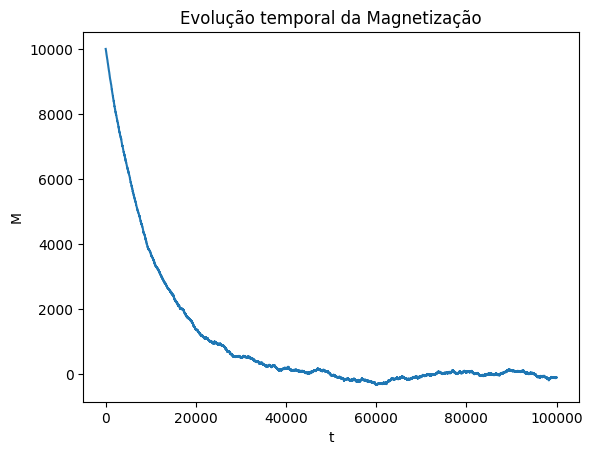

In [164]:
N=10000
m0=1
tmax=100000
p=1/2
tvec, M=evo(spinsample(N,m0),tmax,p)
plt.plot(tvec, M)
plt.xlabel('t')
plt.ylabel('M')
plt.title('Evolução temporal da Magnetização')

In [165]:
N=[100,1000,10000]
m0=np.arange(-1,1,0.25)

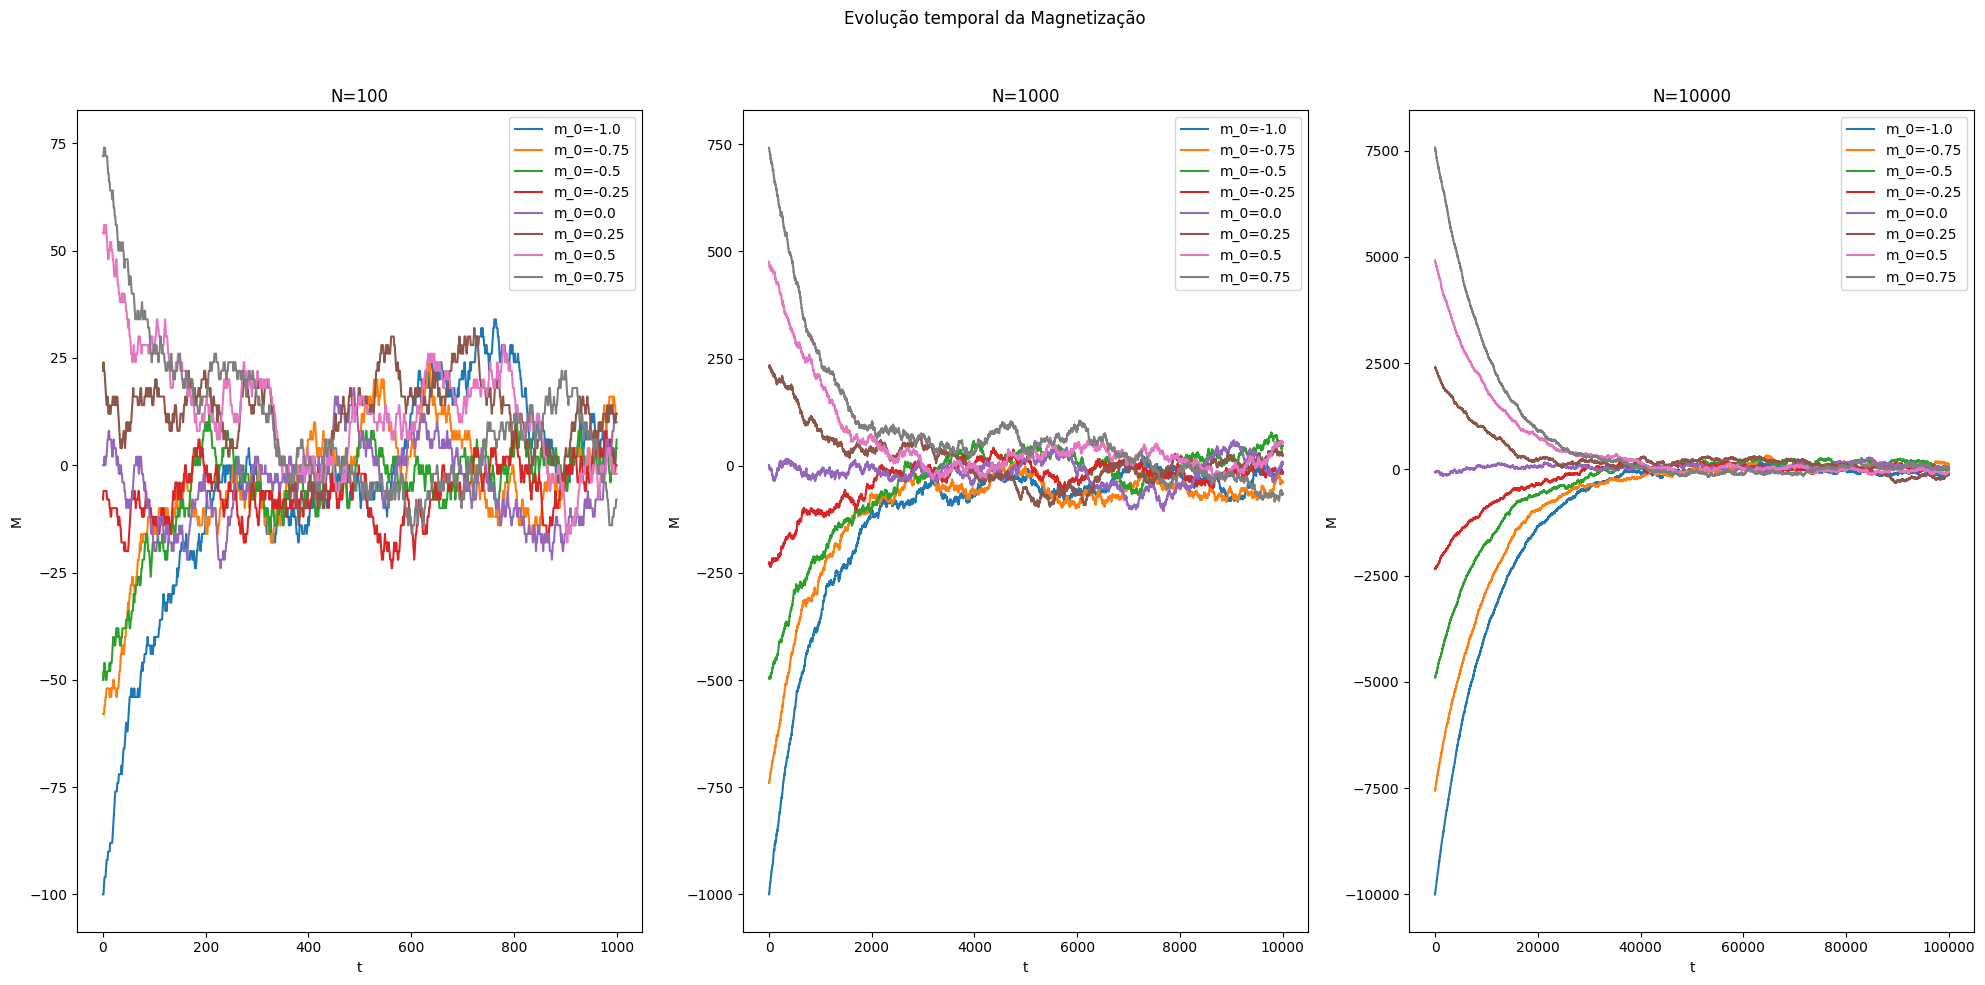

In [166]:
fig, ax = plt.subplots(1,len(N), figsize=(20,10))
for i,n in enumerate(N):
  for m in m0:
    tvec, M=evo(spinsample(n,m),10*n,p)
    ax[i].plot(tvec, M, label={f"m_0={m}"})
    ax[i].set_title(f"N={n}")
    ax[i].legend()
    ax[i].set_xlabel('t')
    ax[i].set_ylabel('M')
fig.suptitle('Evolução temporal da Magnetização')
plt.tight_layout(rect=[0, 0, 1, 0.95])

Variando tanto a magnetização inicial quanto o número de partículas a magnetização do sistema com t>>1 vai para 0.

Para calcular a magnetização média por partícula em função do tempo precisamos gerar um enssemble de medidas.

In [167]:
N=1000
m0=1
ens_l=1000
ens=[]
for i in range(ens_l):
    tvec, M = evo(spinsample(N,m0),10*N,p)
    ens.append(M)
mean_ens=[]
for j in range(len(ens[i])):
  ens_t=[]
  for i in range(ens_l):
    ens_t.append(ens[i][j])
  mean_ens.append(mean(ens_t)/N)

In [168]:
def m_media(t,m0,N):
  return m0*(1-2/N)**t

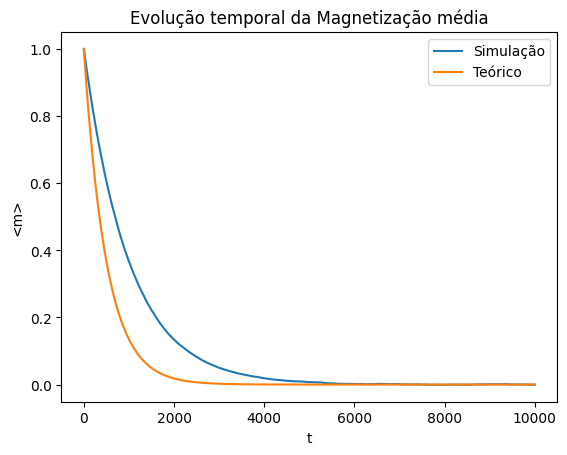

In [169]:

plt.plot(tvec, mean_ens, label={"Simulação"})
plt.plot(tvec, m_media(tvec,m0,N), label={"Teórico"})
plt.xlabel('t')
plt.ylabel('<m>')
plt.title('Evolução temporal da Magnetização média')
plt.legend()

A média da evolução temporal para m0=1 tende para 1 mas uma discrepância ocasionada pelo fato de que aqui consideramos que a partícula escolhida tem uma probabilidade 1/2 de cair trocar de sinal e 1/2 de não acontecer nada o que faz com que o sistema vá mais devagar para o valor de equilibrio m0=0. Na média teórica a probabilidade de ele trocar de sinal era de 100%.

In [170]:
def m_media2(t,m0,N):
  return m0*(1-2/N*p)**t

Podemos comparar a média simulada com essa nova função para média

Text(0.5, 1.0, 'Evolução temporal da Magnetização média')

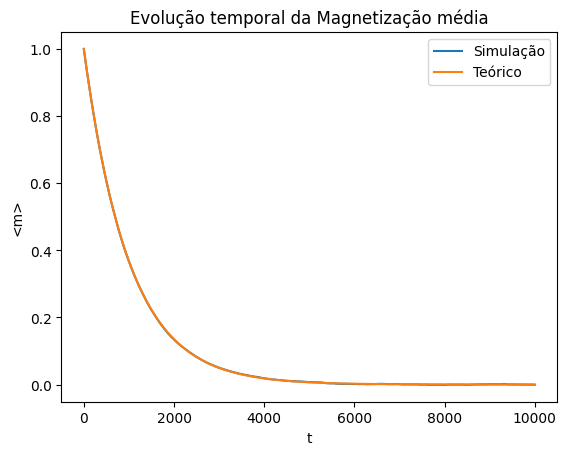

In [171]:
plt.plot(tvec, mean_ens, label={"Simulação"})
plt.plot(tvec, m_media2(tvec,m0,N), label={"Teórico"})
plt.legend()
plt.xlabel('t')
plt.ylabel('<m>')
plt.title('Evolução temporal da Magnetização média')

Aqui já temos sobreposição perfeita entre as duas curvas.

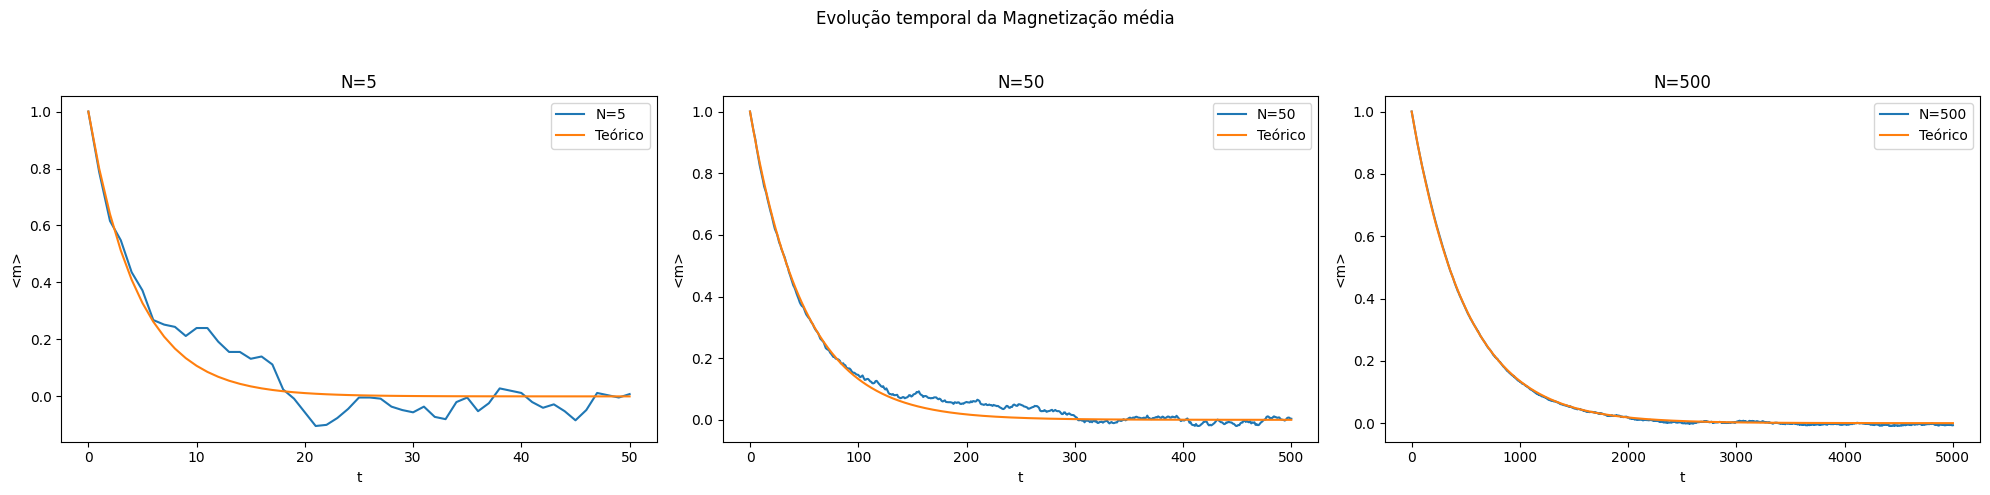

In [176]:
N=[5,50,500]
m0=1
ens_l=100

fig, ax = plt.subplots(1,len(N), figsize=(20,5))
for k,N in enumerate(N):
  ens=[]
  for i in range(ens_l):
    tvec, M = evo(spinsample(N,m0),10*N,p)
    ens.append(M)
  mean_ens=[]
  for j in range(len(ens[i])):
    ens_t=[]
    for i in range(ens_l):
      ens_t.append(ens[i][j])
    mean_ens.append(mean(ens_t)/N)
  ax[k].plot(tvec, mean_ens, label={f"N={N}"})
  ax[k].plot(tvec, m_media2(tvec,m0,N), label={"Teórico"})
  ax[k].set_title(f"N={N}")
  ax[k].legend()
  ax[k].set_xlabel('t')
  ax[k].set_ylabel('<m>')
fig.suptitle('Evolução temporal da Magnetização média')
plt.tight_layout(rect=[0, 0, 1, 0.95])

O tempo de convergência depende do número de partículas mas para um tempo de iteração de 5xN a média normalmente já convergiu para o valor esperado. Para N muito baixos existe uma alta chance de desvios proporcionalmente grandes da méida e conforme N aumenta esse efeito some.

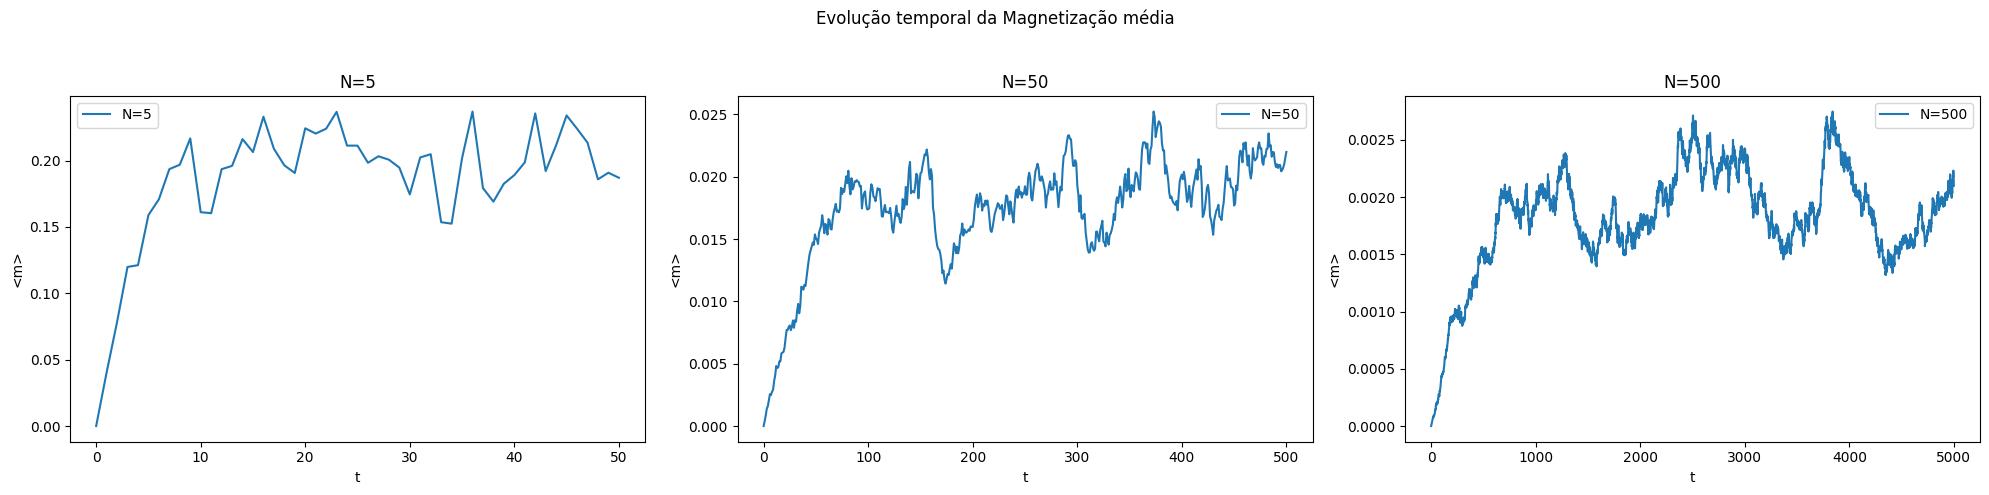

In [179]:
N=[5,50,500]
m0=1
ens_l=100

fig, ax = plt.subplots(1,len(N), figsize=(20,5))
for k,N in enumerate(N):
  ens=[]
  for i in range(ens_l):
    tvec, M = evo(spinsample(N,m0),10*N,p)
    ens.append(M)
  var_ens=[]
  for j in range(len(ens[i])):
    ens_t=[]
    for i in range(ens_l):
      ens_t.append(ens[i][j])
    var_ens.append(variance(ens_t)/(N**2))
  ax[k].plot(tvec, var_ens, label={f"N={N}"})
  ax[k].set_title(f"N={N}")
  ax[k].legend()
  ax[k].set_xlabel('t')
  ax[k].set_ylabel('<m>')
fig.suptitle('Evolução temporal da Magnetização média')
plt.tight_layout(rect=[0, 0, 1, 0.95])

A variância vai para 1/N mostrando que quanto maior o valor de N menor é a disperção em torno da média.

Vamos fazer um corte em t=3*tmax/4 para encontrar a distribuição de equilíbrio.

In [277]:
N = [5,50, 500, 1000]
m0 = 1

In [286]:
ens_l = 1
meq = []

for k, j in enumerate(N):
    meq_N = [] # guarda as trajetórias deste N específico
    for i in range(ens_l):
        tvec, M = evo(spinsample(j, m0), 1000 * j, p)
        meq_N.append(np.array(M) / j) # salva a magnetização por spin (m)
    meq.append(meq_N)


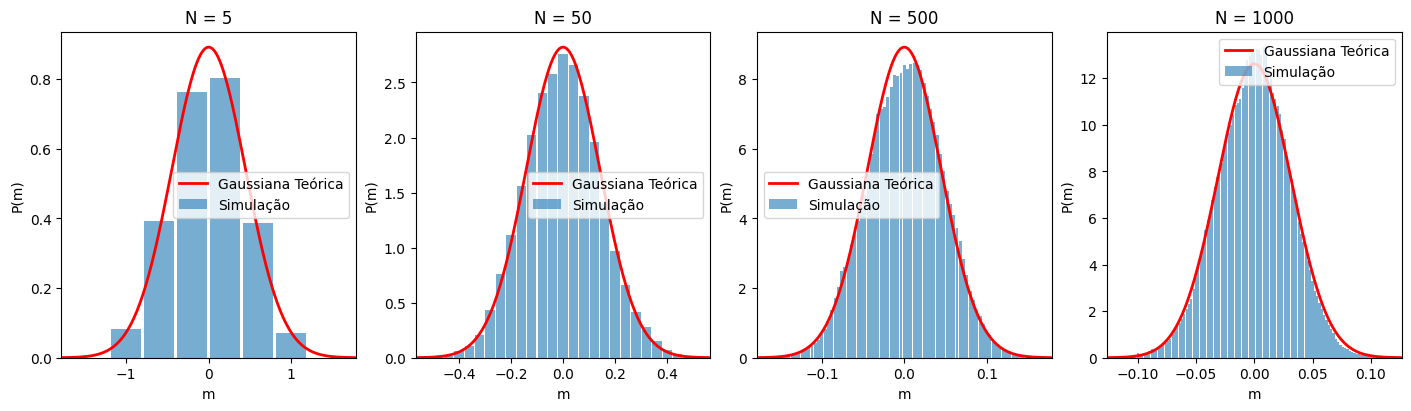

In [287]:
fig, ax = plt.subplots(1, len(N), figsize=(14, 4), constrained_layout=True)

for k, n in enumerate(N):
    vetor = [item for sublista in meq[k] for item in sublista[ 20* n :]]
    val, ocur = np.unique(vetor, return_counts=True)

    delta_m = 2.0 / n
    sigma = 1.0 / np.sqrt(n)

    ax[k].bar(val, (ocur / sum(ocur)) / delta_m, width=delta_m * 0.9, alpha=0.6, color='tab:blue', label='Simulação')
    m_eixo = np.linspace(-4 * sigma, 4 * sigma, 200)
    p_gauss = (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * (m_eixo / sigma)**2)
    ax[k].plot(m_eixo, p_gauss, color='red', linewidth=2, label='Gaussiana Teórica')

    ax[k].set_title(f"N = {n}")
    ax[k].set_xlabel("m")
    ax[k].set_ylabel("P(m)")
    ax[k].set_xlim(-4 * sigma, 4 * sigma)
    ax[k].legend()

plt.show()


Perceba que a envoltória coverge para a guassiana conforme aumentamos N .

Questões



1.   A magnetização sempre converge para 0 para tempos muito longos idependente da magnetização inicial.
2.   O que percebemos é que a uma osciclação da média simulada em torno da média teórica, mas que conforme aumentamos o número de partículas as oscilações em torno da média ficam cada vez menores.
3.  A variância cai com 1/N o que faz com que conforme N se aproxima do limite termodinâmico a variância tende para 0 o que mostra que  o sistema tem flutuações cada vez mais pequenas em torno da média conforme N aumenta.
4. No estado estacionário, a magnetização média $m$ expressa a média de $N$ variáveis aleatórias independentes e identicamente distribuídas com média nula e variância unitária: a Lei dos Grandes Números manifesta-se pelo estreitamento da distribuição $P(m)$ em torno de $\langle m \rangle = 0$, colapsando em uma delta de Dirac conforme $\text{Var}(m) = 1/N \to 0$ no limite $N \to \infty$; simultaneamente, o Teorema Central do Limite dita o perfil dessas flutuações para $N$ finito, garantindo a convergência da distribuição binomial discreta para a densidade contínua Gaussiana $P(m) \approx \sqrt{\frac{N}{2\pi}} \exp\left(-\frac{N m^2}{2}\right)$, processo acelerado pela simetria do sistema

